Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II
Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [40]:
df = pd.read_csv(r'C:\Users\VORPC\Ironhack\classes\labs\week 5\lab-eda-univariate\amz_uk_price_prediction_dataset.csv')
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.
- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.



In [41]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [42]:
crosstab.sort_values(by=True)


isBestSeller,False,True
category,,
eBook Readers & Accessories,246,0
Boating Footwear,140,0
Blank Media Cases & Wallets,243,0
Bedding Collections,6309,0
Boxes & Organisers,911,0
...,...,...
Power & Hand Tools,8353,306
Sports & Outdoors,835935,330
Baby,14709,341


Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [43]:
from scipy.stats import chi2_contingency

In [44]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstab)

In [45]:
a,b,c,d=chi2_contingency(crosstab)

In [46]:
float(chi2_pvalue)

0.0

The p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables

In [47]:
from scipy.stats.contingency import association

In [48]:
association(crosstab, method='cramer')

0.1222829439760564

as the carmers V is between 0.10-0.20 so the strenght of assction is weak 


Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

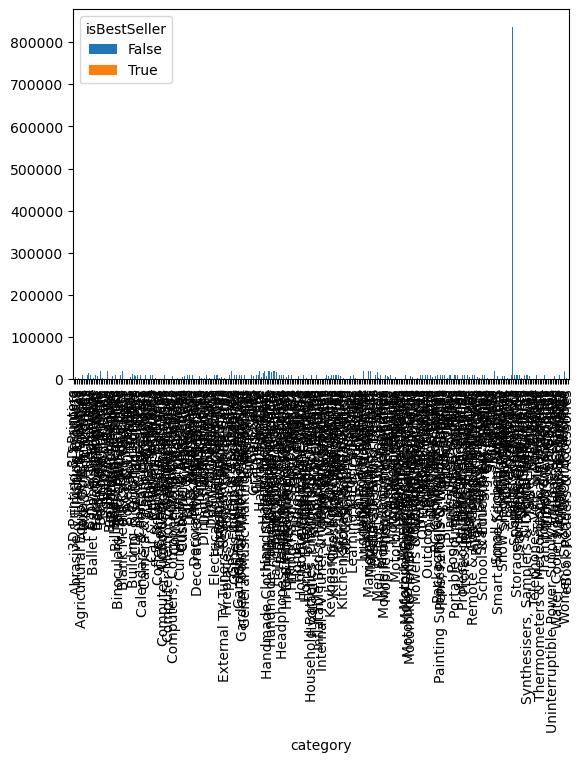

In [49]:
crosstab.plot(kind='bar', stacked=True)
plt.show()

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [60]:
# Calculate IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
df_filtered = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

In [75]:
top_20 = df_filtered['category'].value_counts().head(20).index
filtered = df_filtered[df_filtered['category'].isin(top_20)]


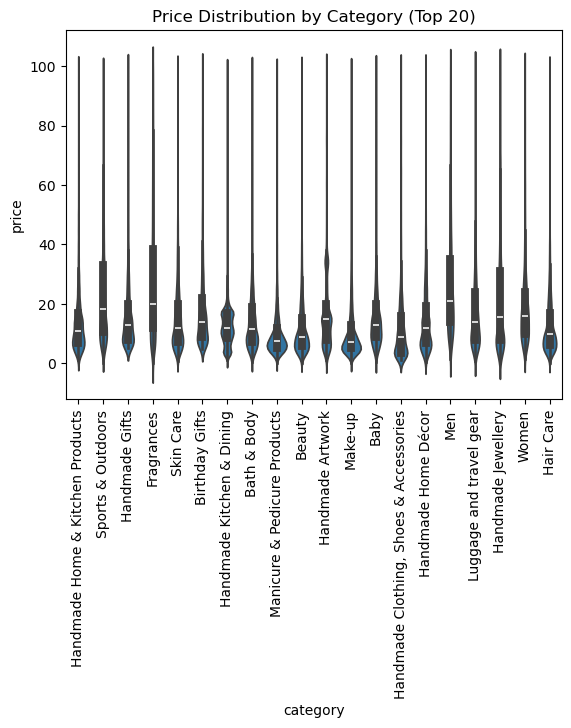

In [77]:
sns.violinplot(x='category', y='price', data=filtered)
plt.xticks(rotation=90)
plt.title('Price Distribution by Category (Top 20)')
plt.show()

Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

In [ ]:
summary =df_filtered.groupby('category')['price'].agg('mean')
sorted_sum = summary.sort_values(ascending=False)
sorted_sum

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [118]:
type(sorted_sum)

pandas.core.series.Series

In [119]:
top_10 = sorted_sum.head(10)


In [122]:
top_10 = pd.DataFrame(top_10)

C:\Users\VORPC\AppData\Local\Temp\ipykernel_3064\3310682805.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10 ,x='category', y = 'price' , palette = 'coolwarm' , errorbar= None)


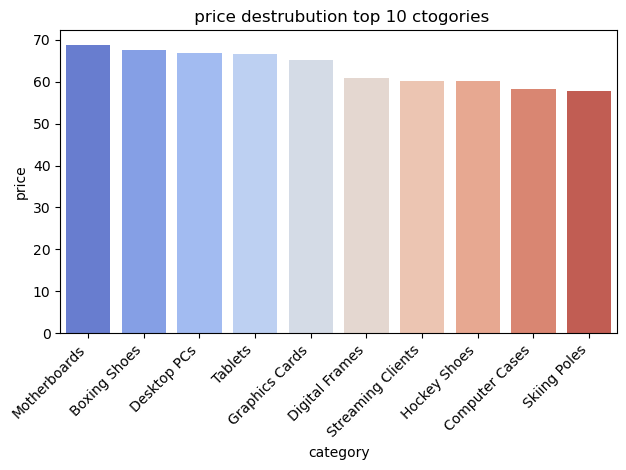

In [124]:
sns.barplot(data=top_10 ,x='category', y = 'price' , palette = 'coolwarm' , errorbar= None)
plt.xticks(rotation=45, ha='right')
plt.title (' price destrubution top 10 ctogories')
plt.tight_layout() 
plt.show()

Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [194]:
median_rating =df_filtered.groupby('category')['stars'].median()
top_10_median_categories = median_rating.nlargest(10).index
filtered_df = df[df['category'].isin(top_10_median_categories)]
print(filtered_df)



             uid        asin  \
301973    319982  B001CJVTLC   
301974    319983  B0C8XWR7BV   
301975    319984  B07ZX5DQB5   
301976    319985  B0CHJ3Z3WG   
301977    319986  B0CBVP21BH   
...          ...         ...   
1957148  2203544  B00NGJCJRE   
1957149  2203545  B00K0CYPRM   
1957150  2203546  B005MEFZE0   
1957151  2203547  B002KCNV3Y   
1957152  2203548  B001GXFN5W   

                                                     title  stars  reviews  \
301973                   Pokémon Assorted Cards, 50 Pieces    4.3    61532   
301974   Pokémon TCG: Scarlet & Violet—151 Card Binder ...    4.2       53   
301975   JML Magnifying Glasses with Light - Magnifier ...    4.0     5409   
301976   Trading Card Binder 4-Pocket, 400 Pockets Trad...    4.0        5   
301977   Panini Premier League 2023/24 Adrenalyn XL Mul...    4.5      139   
...                                                    ...    ...      ...   
1957148                LEGO Technic Compact Tracked Loader    4.5    

C:\Users\VORPC\AppData\Local\Temp\ipykernel_3064\822100500.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_df , x= 'category', y='stars' ,palette='coolwarm' , legend=False )


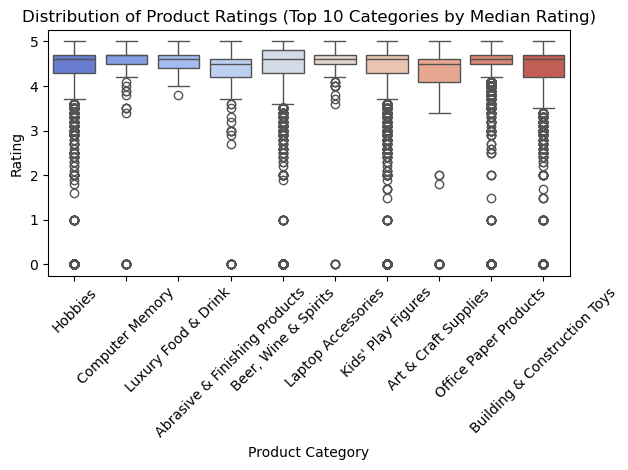

In [197]:
sns.boxplot(data=filtered_df , x= 'category', y='stars' ,palette='coolwarm' , legend=False )
plt.title('Distribution of Product Ratings (Top 10 Categories by Median Rating)')
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

In [198]:
# Calculating the Pearson correlation coefficient
round(float(df["price"].corr(df["stars"], method="pearson")), 2)

-0.12

In [199]:
# Calculating the Spearman rank correlation
round(float(df["price"].corr(df["stars"], method="spearman")), 2)

-0.13

we can see with the spearman and pearson correlcation coeficient that there is a weak lienear and monotonic correlation 

Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.


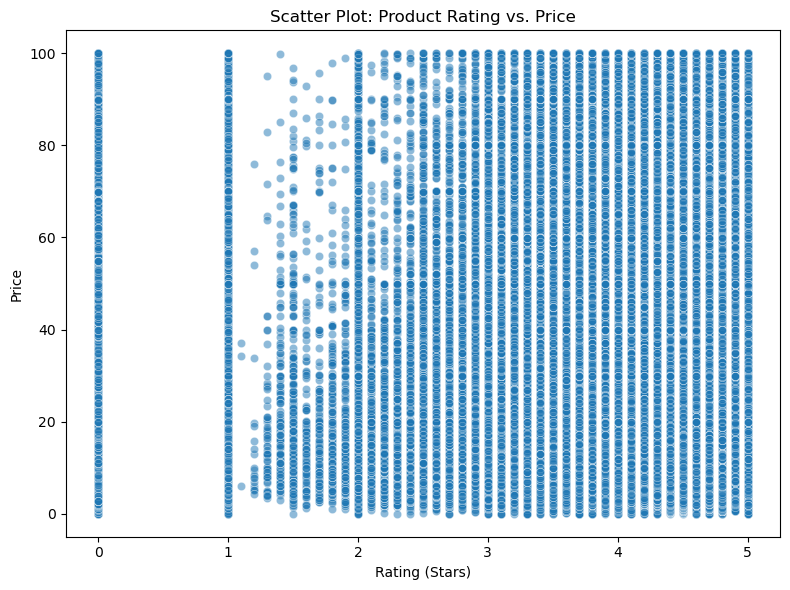

In [215]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_filtered, x='stars', y='price', alpha=0.5)
plt.title('Scatter Plot: Product Rating vs. Price')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()


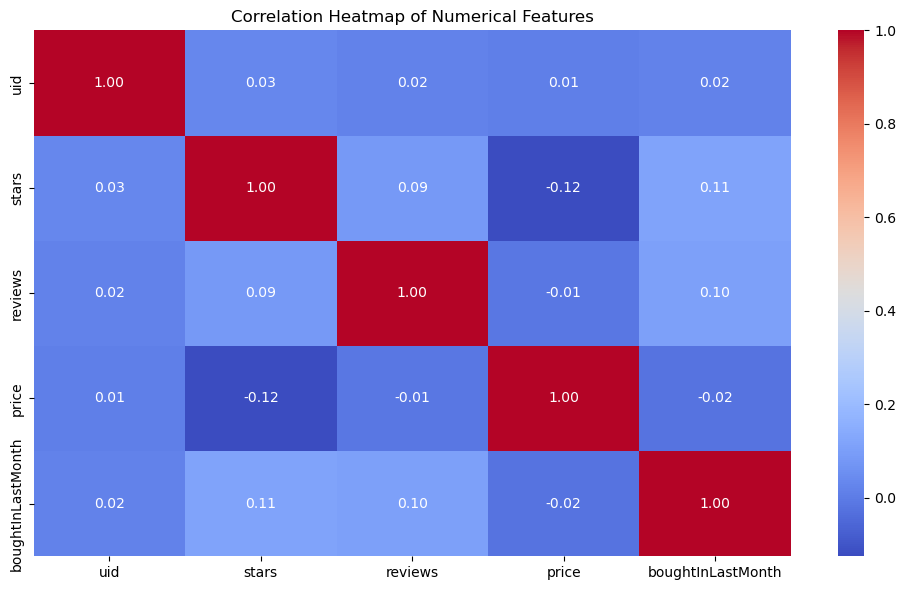

In [211]:
corr_matrix = df.select_dtypes(include='number').corr()

# Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()


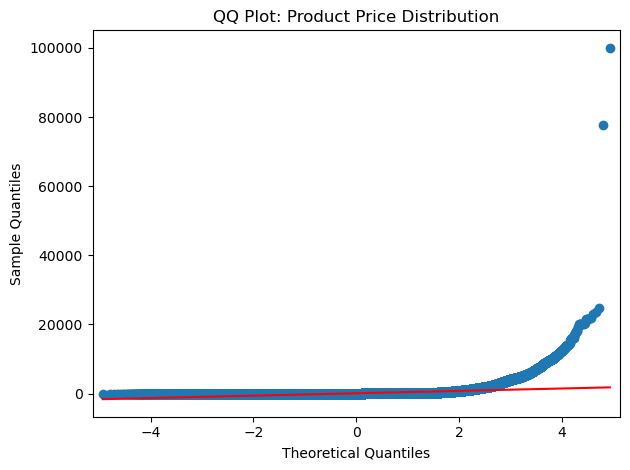

In [219]:
import statsmodels.api as sm

sm.qqplot(df['price'], line= 's')
plt.title('QQ Plot: Product Price Distribution')
plt.tight_layout()
plt.show()
